# Particle binning
*Keyed sums: the mass in each cell*

A simulation tracks many particles; you want the mass in each cell of a mesh, and how many particles fell there.
That is a keyed sum: every particle adds its weight at the key of its cell. Many particles share a key, and hawk
combines them so there is no race.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [Across lanes](../across_lanes)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import plot_style, show
plot_style()

## Particles

Positions in `[0, 1)` drawn from a skewed distribution, each with a weight.

In [3]:
from nb_helpers import gpu_available
import numpy as np

NB = 16                                            # cells
n = 20_000 if not gpu_available() else 20_000_000
rng = np.random.default_rng(4)
x = rng.beta(2, 5, size=n)
w = rng.uniform(0.5, 1.5, size=n)
print(f"{n} particles, {NB} cells")

20000 particles, 16 cells


## The particle's words

Say the vocabulary first. A particle has a position `x` and a weight `w`; once its cell is known, the cell number is a key, and when the particles are kept sorted by cell it is a `Sorted[Index]`. Declare those once as a `KernelKind`. The kernels below are written in these names, and a kernel takes only the ones it needs.

In [4]:
from hawk import Index, Scalar, Sorted
from hawk.ext import DATA_ONLY, KernelKind


class Particle(KernelKind, slug="particle"):
    x: Scalar               # position in [0, 1)
    w: Scalar               # weight
    cell: Sorted[Index]     # the cell number, for particles kept sorted by cell
    guard = DATA_ONLY

Particle

__main__.Particle

## The kernel

`m.index(x * NB, NB)` turns a position into a cell number, kept inside `0 .. NB-1`. `hawk.scatter(mass)[cell] += w`
adds the weight there. A sink declared with a name and an extent, `Mutable["bin":NB]`, is an output you do not have to
supply: it starts at zero.

`policy="compensated"` asks for the tightest sum: the error in a cell is at most `k * eps * sum|w|`, with `k = 1` on the card. The default, `"auto"`, is the fast
form. See [Across lanes](../across_lanes) for the three policies.

In [5]:
import eagle
import hawk
import hawk.math as m
from hawk import Index, Mutable, Scalar, Sorted

@Particle
def deposit(x, w, mass: Mutable["bin":NB], count: Mutable["bin":NB]):
    cell = m.index(x * NB, NB)
    hawk.scatter(mass, policy="compensated")[cell] += w
    hawk.scatter(count)[cell] += 1.0

out = eagle.deploy(deposit).run(x=x, w=w)
cell = np.minimum((x * NB).astype(int), NB - 1)
assert np.array_equal(out["count"], np.bincount(cell, minlength=NB))
print("count matches NumPy; total count", int(out["count"].sum()))

count matches NumPy; total count 20000


## Check against the exact sum

`math.fsum` gives each cell's correctly rounded sum. The compensated mass must stay within `eps * sum|w|` of it
(the weights are positive, so `sum|w|` is the cell's mass), and nothing may be lost: the cells add up to the total
weight and the counts to `n`.

In [6]:
import math

exact = np.array([math.fsum(w[cell == k]) for k in range(NB)])
bound = np.finfo(float).eps * np.bincount(cell, np.abs(w), NB)
assert np.all(np.abs(out["mass"] - exact) <= bound)
assert math.isclose(out["mass"].sum(), math.fsum(w), rel_tol=1e-12) and out["count"].sum() == n
used = bound > 0                                   # an empty cell has nothing to bound
print(f"worst cell error {np.max(np.abs(out['mass'] - exact)[used] / bound[used]):.2f} of the bound; mass and count conserved")

worst cell error 0.00 of the bound; mass and count conserved


## When the keys are already sorted

If the particles are sorted by cell, equal keys sit side by side. Particle-in-cell codes keep their particles sorted by cell, which is when this applies. Declare the key as `Sorted[Index]` and hawk adds each
run of equal keys once, instead of once per particle. The promise is yours: values that decrease are not detected unless
you set `HAWK_CHECK_SORTED`.

In [7]:
@Particle
def deposit_sorted(cell, w, mass: Mutable["bin":NB]):
    hawk.scatter(mass)[cell] += w

order = np.argsort(cell, kind="stable")
mass_sorted = eagle.deploy(deposit_sorted).run(cell=cell[order].astype(np.int32), w=w[order])
assert np.all(np.abs(mass_sorted - exact) <= bound)        # the default sum meets the same bound
print("sorted keys give the same mass")

sorted keys give the same mass


## The histogram

The positions follow a Beta(2, 5) law, whose cumulative form is `1 - (1-x)^5 (1+5x)`; the mean weight is 1. The
outlines show the expected counts and mass density.


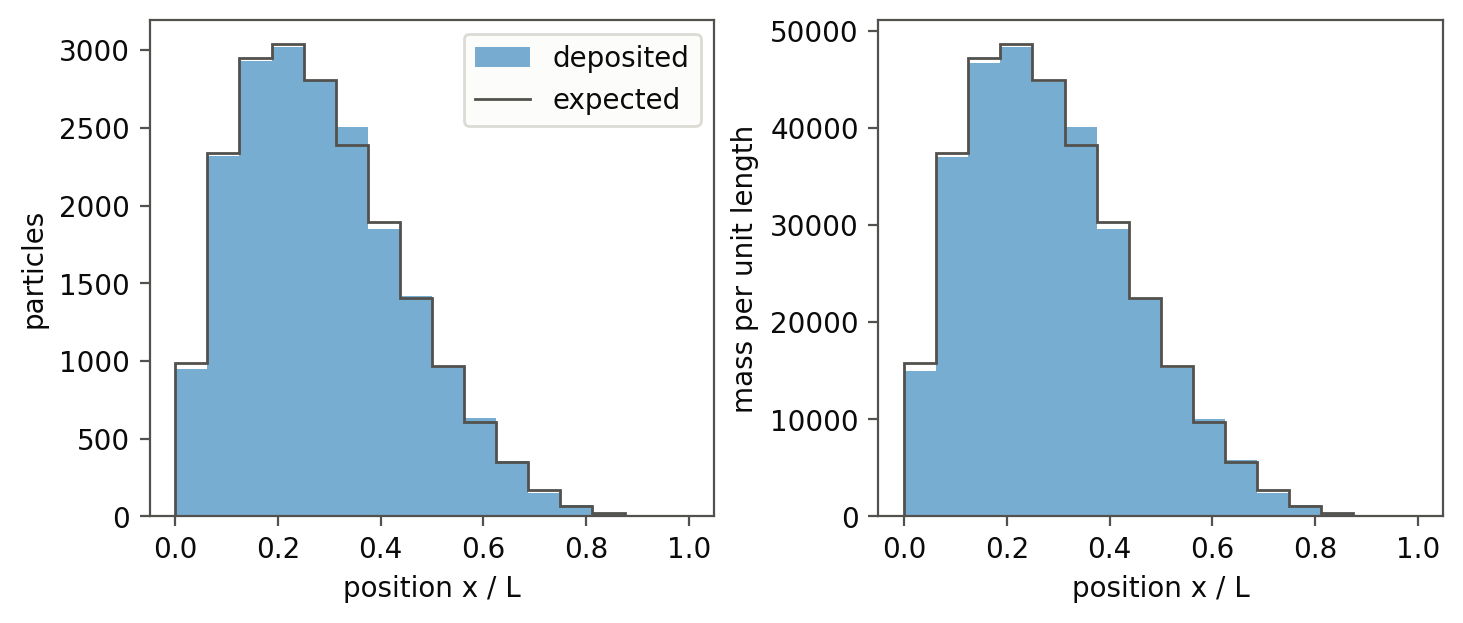
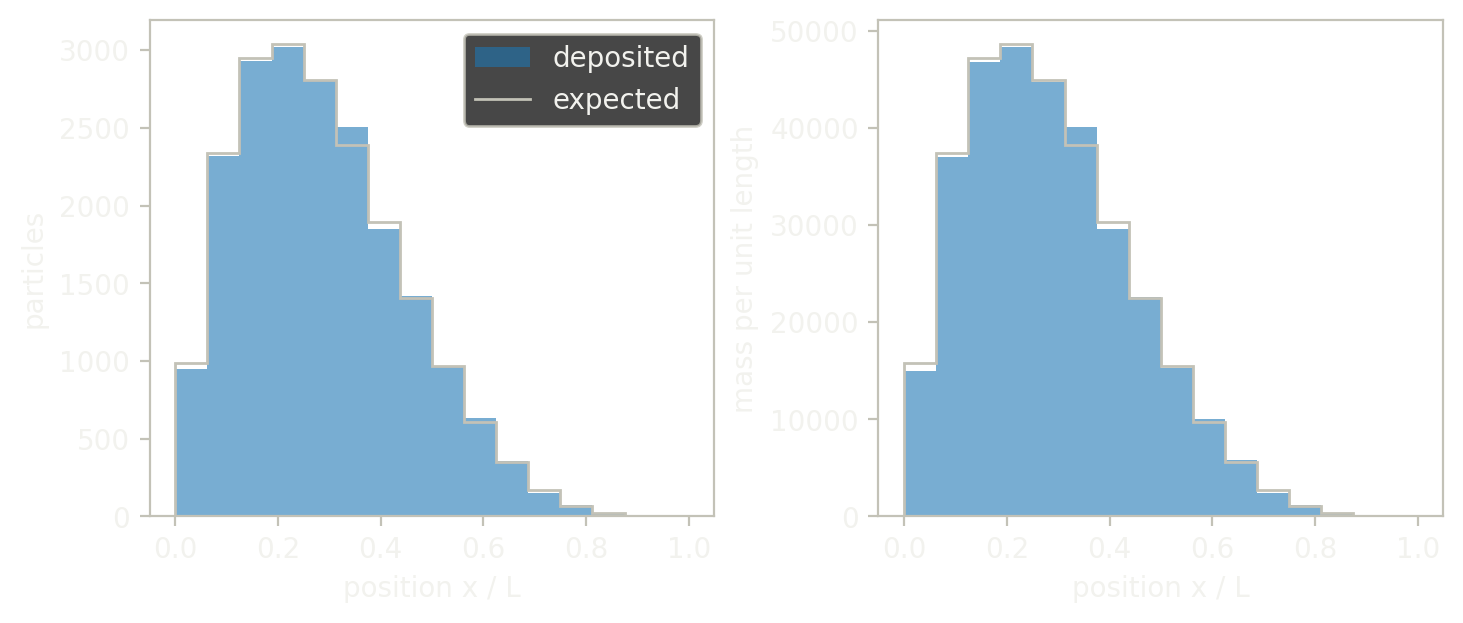

In [8]:
import matplotlib.pyplot as plt

edges = np.arange(NB + 1) / NB
cdf = 1 - (1 - edges) ** 5 * (1 + 5 * edges)
expect = n * np.diff(cdf)                          # expected particles per cell
fig, (a0, a1) = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True)
a0.stairs(out["count"], edges, fill=True, alpha=0.6, label="deposited")
a0.stairs(expect, edges, color="#898781", label="expected")
a0.set_xlabel("position x / L")
a0.set_ylabel("particles")
a0.legend()
a1.stairs(out["mass"] * NB, edges, fill=True, alpha=0.6)
a1.stairs(expect * NB, edges, color="#898781")
a1.set_xlabel("position x / L")
a1.set_ylabel("mass per unit length")
show(fig, "Particle count and mass per unit length against the expected Beta distribution")

## What just happened

- `hawk.scatter(sink)[key] += v` is a keyed sum; many lanes may share a key.
- `policy="compensated"` picked the tightest sum for the mass; the count used the default.
- `Sorted[Index]` told hawk the keys never decrease, so it added each run of equal keys once.
- The mass stays within `eps * sum|w|` of the exactly rounded sum in every cell, and the totals are conserved.

[Across lanes](../across_lanes) has the other policies and the sums over axes of a grid.